# EDA Kualitas Udara Kota di Asia Tenggara
## Distribusi AQI, perbandingan negara, dan profil polutan

**Tugas Besar Visualisasi Data — naskah analisis dalam bahasa Indonesia**  
Identitas mahasiswa/kelompok: **isi sebelum dikumpulkan**.

Tujuan: (1) menggambarkan distribusi AQI dan kategorinya; (2) membandingkan AQI antarkelompok negara; (3) mengeksplorasi pola bersama empat indeks polutan. Setiap visualisasi disertai interpretasi dan batasan.

Analisis ini mengadaptasi topik notebook unggahan sebagai referensi; kode EDA disusun ulang untuk dijalankan lokal tanpa geocoding, instalasi paket di sel, maupun model prediksi. Semua hasil dihitung ulang dari CSV, bukan menyalin output notebook referensi.

## 1. Sumber, unit analisis, dan batasan

Data: `global_air_pollution_dataset.csv`, diambil dari ZIP unggahan pengguna. Halaman sumber yang diberikan pengguna: [https://www.kaggle.com/code/kimpilso/asean-air-pollution-capstone-g5-ds-greatedu/input](https://www.kaggle.com/code/kimpilso/asean-air-pollution-capstone-g5-ds-greatedu/input) (Kaggle, notebook kimpilso). Ini adalah rujukan halaman input, bukan klaim bahwa penulis notebook merupakan pengumpul data primer. URL dataset spesifik, lisensi, metode pengumpulan, serta waktu pengukuran tidak tercantum di CSV; periksa metadata sumber sebelum redistribusi publik.

Satu baris merepresentasikan catatan kota dan negara. Nilai CO, ozon, NO2, dan PM2.5 adalah **subindeks AQI**, bukan konsentrasi fisik seperti µg/m³. CSV tidak memiliki tanggal atau koordinat: analisis tidak menyimpulkan tren waktu, paparan penduduk, peringkat nasional resmi, atau keadaan udara terkini.

Cakupan operasional: sepuluh negara dalam filter ASEAN notebook referensi. Brunei tidak memiliki baris; Timor-Leste tidak dimasukkan ke filter referensi ini. Istilah Asia Tenggara di sini merujuk subset yang tersedia, bukan seluruh wilayah atau pernyataan keanggotaan ASEAN pada tahun berjalan.

In [1]:
from pathlib import Path
import hashlib, json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
sns.set_theme(style='whitegrid', palette='colorblind', font_scale=1.0)
DATA = Path('data/global_air_pollution_dataset.csv')
OUT = Path('figures'); OUT.mkdir(exist_ok=True)
df = pd.read_csv(DATA)
numeric = ['AQI Value', 'CO AQI Value', 'Ozone AQI Value', 'NO2 AQI Value', 'PM2.5 AQI Value']
pollutants = numeric[1:]
assert df.shape[1] == 12 and set(numeric).issubset(df.columns)
print('SHA256:', hashlib.sha256(DATA.read_bytes()).hexdigest())
print('Ukuran global:', df.shape)
display(df.head())
def savefig(name):
    plt.tight_layout()
    plt.savefig(OUT / (name + '.png'), dpi=180, bbox_inches='tight')
    plt.show()


SHA256: e1fc6e682edb8a2102d87e182b844fc8cde49e10763c0ef4293e510bbe240f69
Ukuran global: (23463, 12)


,Country,City,AQI Value,AQI Category,CO AQI Value,CO AQI Category,Ozone AQI Value,Ozone AQI Category,NO2 AQI Value,NO2 AQI Category,PM2.5 AQI Value,PM2.5 AQI Category
0,Russian Federation,Praskoveya,51,Moderate,1,Good,36,Good,0,Good,51,Moderate
1,Brazil,Presidente Dutra,41,Good,1,Good,5,Good,1,Good,41,Good
2,Italy,Priolo Gargallo,66,Moderate,1,Good,39,Good,2,Good,66,Moderate
3,Poland,Przasnysz,34,Good,1,Good,34,Good,0,Good,20,Good
4,France,Punaauia,22,Good,0,Good,22,Good,0,Good,6,Good


## 2. Audit dan persiapan data

Nilai ekstrem dipertahankan karena dapat menjadi bagian penting dari kasus polusi; winsorization tidak dilakukan tanpa bukti kesalahan ukur. Negara kosong tidak ditebak. Baris tersebut dikecualikan hanya dari analisis regional, sambil tetap dilaporkan pada audit global. Nama negara distandarkan sebelum filter agar Vietnam dan Laos tidak hilang seperti pada notebook awal.

In [2]:
audit = pd.DataFrame({'tipe': df.dtypes.astype(str), 'kosong': df.isna().sum(), 'unik': df.nunique()})
display(audit)
print('Duplikat baris penuh:', int(df.duplicated().sum()))
print('Duplikat pasangan negara-kota:', int(df.duplicated(['Country', 'City']).sum()))
print('Nilai negatif per kolom:', (df[numeric] < 0).sum().to_dict())
region = ['Brunei', 'Cambodia', 'Indonesia', 'Laos', 'Malaysia', 'Myanmar', 'Philippines', 'Singapore', 'Thailand', 'Vietnam']
work = df.copy()
work['Country'] = work['Country'].replace({'Viet Nam':'Vietnam', "Lao People's Democratic Republic":'Laos'})
asean = work.loc[work['Country'].isin(region)].copy()
assert not asean[numeric].isna().any().any()
assert (asean[numeric] >= 0).all().all()
asean.to_csv('data/asia_tenggara_aqi.csv', index=False)
coverage = asean.groupby('Country')['AQI Value'].agg(n='size', median='median', mean='mean', minimum='min', maximum='max')
coverage.to_csv('data/ringkasan_negara.csv')
display(coverage.round(2))
display(Markdown(f"Data global memiliki **{len(df):,} baris**, **{df.Country.nunique()} negara bernama**, {df.Country.isna().sum()} negara kosong dan {df.City.isna().sum()} kota kosong. Subset berisi **{len(asean):,} baris** dari **{asean.Country.nunique()} negara**, tanpa nilai kosong. Negara filter tanpa data: **{', '.join(sorted(set(region)-set(asean.Country)))}**."))


,tipe,kosong,unik
Country,object,427,175
City,object,1,23462
AQI Value,int64,0,347
AQI Category,object,0,6
CO AQI Value,int64,0,34
CO AQI Category,object,0,3
Ozone AQI Value,int64,0,213
Ozone AQI Category,object,0,5
NO2 AQI Value,int64,0,59
NO2 AQI Category,object,0,2


Duplikat baris penuh: 0
Duplikat pasangan negara-kota: 0
Nilai negatif per kolom: {'AQI Value': 0, 'CO AQI Value': 0, 'Ozone AQI Value': 0, 'NO2 AQI Value': 0, 'PM2.5 AQI Value': 0}


,n,median,mean,minimum,maximum
Country,,,,,
Cambodia,12,46.0,45.25,21,73
Indonesia,379,74.0,93.04,10,297
Laos,8,43.5,43.50,23,75
Malaysia,125,72.0,81.62,15,209
Myanmar,59,34.0,40.17,15,145
Philippines,337,54.0,61.20,14,165
Singapore,1,91.0,91.00,91,91
Thailand,246,50.5,53.58,18,164
Vietnam,60,69.0,87.05,21,194


Data global memiliki **23,463 baris**, **175 negara bernama**, 427 negara kosong dan 1 kota kosong. Subset berisi **1,227 baris** dari **9 negara**, tanpa nilai kosong. Negara filter tanpa data: **Brunei**.

### Kamus data

`Country` dan `City`: label wilayah; `AQI Value` dan `AQI Category`: indeks gabungan serta label kategori yang tersedia. Empat pasangan kolom `CO`, `Ozone`, `NO2`, dan `PM2.5` berisi subindeks dan kategori masing-masing polutan. Tidak ada bobot populasi atau metadata alat ukur. Median negara dihitung atas baris kota yang tersedia dengan bobot sama, bukan rata-rata paparan penduduk.

## 3. Univariate — satu variabel
### 3.1 Distribusi numerik AQI
Histogram menunjukkan bentuk distribusi dan boxplot memperlihatkan median, sebaran, serta nilai ekstrem. Keduanya memakai AQI asli.

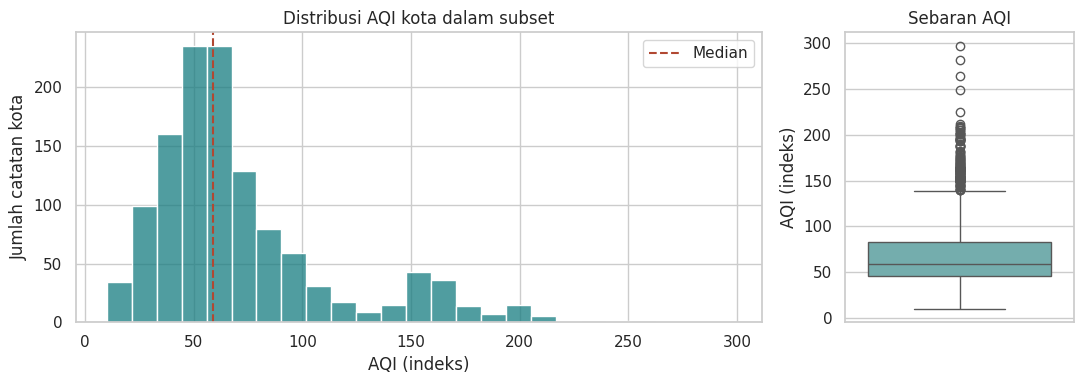

,AQI Value,CO AQI Value,Ozone AQI Value,NO2 AQI Value,PM2.5 AQI Value
count,1227.00,1227.00,1227.00,1227.00,1227.00
mean,71.59,1.51,32.52,2.06,70.48
std,42.41,2.61,29.60,5.74,40.71
min,10.00,0.00,1.00,0.00,5.00
25%,45.50,1.00,20.00,0.00,45.50
50%,59.00,1.00,25.00,0.00,59.00
75%,83.00,2.00,33.00,1.00,82.50
max,297.00,67.00,209.00,63.00,297.00


**Analisis:** median AQI **59.0**, rata-rata **71.6**, dan rentang **10–297**. Separuh catatan berada pada 45.5–83.0. Rata-rata di atas median konsisten dengan ekor kanan; kota dengan AQI tinggi dipertahankan, bukan otomatis dianggap kesalahan.

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={'width_ratios':[3,1]})
sns.histplot(data=asean, x='AQI Value', bins=25, ax=axes[0], color='#167c80')
axes[0].axvline(asean['AQI Value'].median(), color='#b14832', linestyle='--', label='Median')
axes[0].legend(); axes[0].set(xlabel='AQI (indeks)', ylabel='Jumlah catatan kota', title='Distribusi AQI kota dalam subset')
sns.boxplot(data=asean, y='AQI Value', ax=axes[1], color='#6ab7b7')
axes[1].set(ylabel='AQI (indeks)', title='Sebaran AQI')
savefig('01_distribusi')
display(asean[numeric].describe().round(2))
q = asean['AQI Value'].quantile([.25,.5,.75])
display(Markdown(f"**Analisis:** median AQI **{q.loc[.5]:.1f}**, rata-rata **{asean['AQI Value'].mean():.1f}**, dan rentang **{asean['AQI Value'].min()}–{asean['AQI Value'].max()}**. Separuh catatan berada pada {q.loc[.25]:.1f}–{q.loc[.75]:.1f}. Rata-rata di atas median konsisten dengan ekor kanan; kota dengan AQI tinggi dipertahankan, bukan otomatis dianggap kesalahan."))


### 3.2 Distribusi kategori AQI
Gunakan kategori yang disediakan CSV. Batas kategori diperiksa dengan interval tanpa celah: ≤50, 51–100, 101–150, 151–200, 201–300, >300. Ini memperbaiki kondisi `>51`, `>101`, dan seterusnya pada referensi, yang dapat menghilangkan nilai batas.

Ketidaksesuaian kategori: 12


,Country,City,AQI Value,AQI Category,kategori_interval
94,Vietnam,Thai Nguyen,150,Unhealthy,Unhealthy for Sensitive Groups
2032,Indonesia,Balung,100,Unhealthy for Sensitive Groups,Moderate
2539,Philippines,Titay,100,Unhealthy for Sensitive Groups,Moderate
8982,Indonesia,Pemalang,100,Unhealthy for Sensitive Groups,Moderate
10242,Philippines,Santa Ana,150,Unhealthy,Unhealthy for Sensitive Groups
11812,Indonesia,Pecangakan,150,Unhealthy,Unhealthy for Sensitive Groups
11845,Malaysia,Bukit Mertajam,150,Unhealthy,Unhealthy for Sensitive Groups
14208,Malaysia,Sungai Petani,150,Unhealthy,Unhealthy for Sensitive Groups
19368,Malaysia,Juru,150,Unhealthy,Unhealthy for Sensitive Groups
21790,Malaysia,Alor Gajah,100,Unhealthy for Sensitive Groups,Moderate


**Temuan kualitas data:** 12 label berbeda dari interval audit, berada di batas kategori. Label asli tetap dipakai untuk grafik kategori dan tidak ditimpa. Persentase AQI >100 dihitung dari angka AQI, sehingga tidak disamakan dengan penjumlahan label kategori yang inkonsisten.

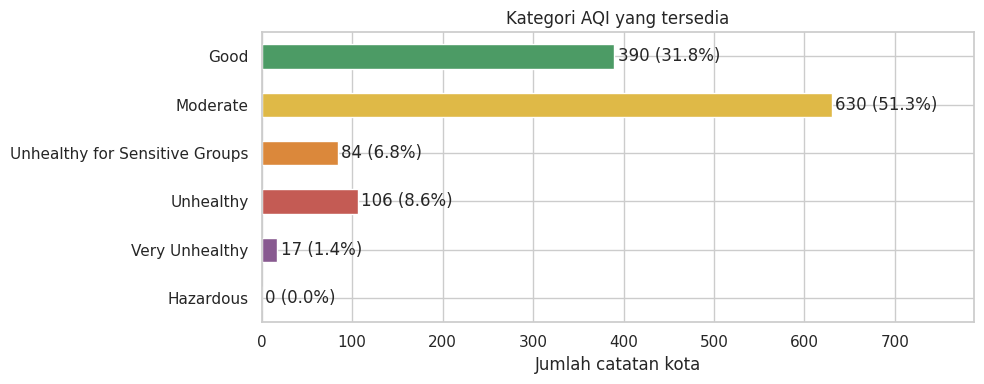

**Analisis:** kategori terbanyak adalah **Moderate**, sebanyak **630 (51.3%)**. Sebanyak **16.5%** catatan memiliki AQI >100. Persentase tersebut adalah bagian dari sampel kota, bukan persentase penduduk yang terpapar.

In [4]:
category_order = ['Good', 'Moderate', 'Unhealthy for Sensitive Groups', 'Unhealthy', 'Very Unhealthy', 'Hazardous']
derived = pd.cut(asean['AQI Value'], bins=[-np.inf,50,100,150,200,300,np.inf], labels=category_order)
mismatch = int((derived.astype(str) != asean['AQI Category']).sum())
print('Ketidaksesuaian kategori:', mismatch)
category_audit = asean.loc[derived.astype(str) != asean['AQI Category'], ['Country','City','AQI Value','AQI Category']].copy()
category_audit['kategori_interval'] = derived.loc[category_audit.index].astype(str)
category_audit.to_csv('data/audit_kategori.csv', index=False)
display(category_audit)
display(Markdown(f'**Temuan kualitas data:** {mismatch} label berbeda dari interval audit, berada di batas kategori. Label asli tetap dipakai untuk grafik kategori dan tidak ditimpa. Persentase AQI >100 dihitung dari angka AQI, sehingga tidak disamakan dengan penjumlahan label kategori yang inkonsisten.'))
counts = asean['AQI Category'].value_counts().reindex(category_order, fill_value=0)
fig, ax = plt.subplots(figsize=(10,4))
counts.plot.barh(ax=ax, color=['#4c9b65','#dfb947','#db883b','#c45b54','#885a90','#704255'])
for i, v in enumerate(counts): ax.text(v+4, i, f'{v} ({100*v/len(asean):.1f}%)', va='center')
ax.set(xlabel='Jumlah catatan kota', ylabel='', title='Kategori AQI yang tersedia'); ax.set_xlim(0, counts.max()*1.25); ax.invert_yaxis()
savefig('02_kategori')
share_above100 = (asean['AQI Value'] > 100).mean()*100
display(Markdown(f"**Analisis:** kategori terbanyak adalah **{counts.idxmax()}**, sebanyak **{counts.max()} ({counts.max()/len(asean)*100:.1f}%)**. Sebanyak **{share_above100:.1f}%** catatan memiliki AQI >100. Persentase tersebut adalah bagian dari sampel kota, bukan persentase penduduk yang terpapar."))


## 4. Bivariate — hubungan dua variabel
### 4.1 Negara dan AQI
Boxplot membandingkan distribusi, bukan hanya rata-rata. Label mencantumkan ukuran sampel agar perbedaan cakupan terlihat.

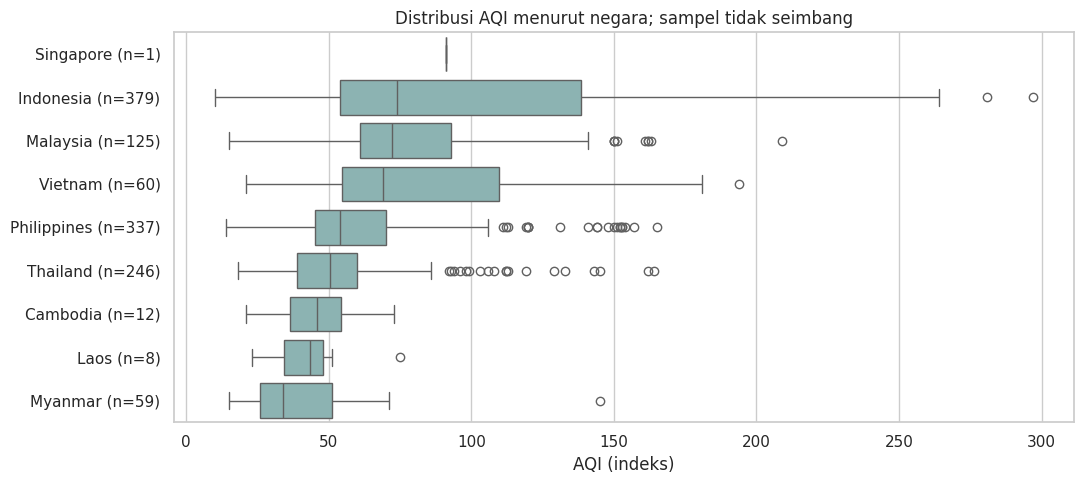

**Analisis:** Indonesia memiliki **379** catatan, sedangkan Singapore hanya **1**. Median terbesar pada subset adalah Singapore (**91.0**); median terkecil Myanmar (**34.0**). Nilai tunggal Singapore tidak mewakili distribusi nasional. Perbedaan ini deskriptif; tidak membuktikan dampak kebijakan atau perbedaan paparan penduduk.

In [5]:
order = coverage.sort_values('median', ascending=False).index.tolist()
fig, ax = plt.subplots(figsize=(11,5))
sns.boxplot(data=asean, x='AQI Value', y='Country', order=order, color='#85bab8', ax=ax)
ax.set_yticks(range(len(order)), [f'{c} (n={coverage.loc[c,"n"]})' for c in order])
ax.set(xlabel='AQI (indeks)', ylabel='', title='Distribusi AQI menurut negara; sampel tidak seimbang')
savefig('03_negara')
largest = coverage['n'].idxmax(); smallest = coverage['n'].idxmin()
display(Markdown(f"**Analisis:** {largest} memiliki **{coverage.loc[largest,'n']}** catatan, sedangkan {smallest} hanya **{coverage.loc[smallest,'n']}**. Median terbesar pada subset adalah {order[0]} (**{coverage.loc[order[0],'median']:.1f}**); median terkecil {order[-1]} (**{coverage.loc[order[-1],'median']:.1f}**). Nilai tunggal Singapore tidak mewakili distribusi nasional. Perbedaan ini deskriptif; tidak membuktikan dampak kebijakan atau perbedaan paparan penduduk."))


### 4.2 PM2.5 AQI dan AQI total
Scatterplot memeriksa hubungan dua indeks. Garis diagonal adalah kesamaan nilai, bukan model regresi.

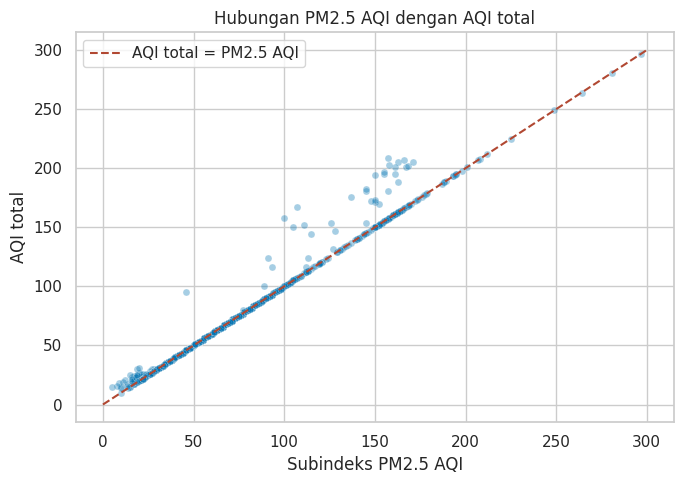

**Analisis:** korelasi Pearson **r=0.990**. AQI total sama dengan maksimum empat subindeks pada **100.0%** baris dan sama dengan PM2.5 AQI pada **93.5%** baris (termasuk kemungkinan seri). Karena hubungan struktural ini, korelasi tidak menjadi bukti PM2.5 menyebabkan seluruh variasi kualitas udara. Model yang memprediksi AQI total dari komponen penyusunnya berisiko hanya mempelajari definisi indeks.

In [6]:
fig, ax = plt.subplots(figsize=(7,5))
sns.scatterplot(data=asean, x='PM2.5 AQI Value', y='AQI Value', alpha=.35, s=25, ax=ax)
ax.plot([0,300], [0,300], '--', color='#b14832', label='AQI total = PM2.5 AQI')
ax.legend(); ax.set(xlabel='Subindeks PM2.5 AQI', ylabel='AQI total', title='Hubungan PM2.5 AQI dengan AQI total')
savefig('04_pm25_aqi')
max_match = (asean['AQI Value'] == asean[pollutants].max(axis=1)).mean()
pm_match = (asean['AQI Value'] == asean['PM2.5 AQI Value']).mean()
r = asean[['AQI Value','PM2.5 AQI Value']].corr().iloc[0,1]
display(Markdown(f"**Analisis:** korelasi Pearson **r={r:.3f}**. AQI total sama dengan maksimum empat subindeks pada **{max_match:.1%}** baris dan sama dengan PM2.5 AQI pada **{pm_match:.1%}** baris (termasuk kemungkinan seri). Karena hubungan struktural ini, korelasi tidak menjadi bukti PM2.5 menyebabkan seluruh variasi kualitas udara. Model yang memprediksi AQI total dari komponen penyusunnya berisiko hanya mempelajari definisi indeks."))


## 5. Multivariate — pola bersama beberapa variabel
### 5.1 Scatterplot tiga variabel
CO AQI dan PM2.5 AQI ditampilkan sebagai koordinat, negara sebagai warna. Hubungan ini tidak menggunakan AQI total sebagai sumbu sehingga tidak sekadar menggambarkan maksimum subindeks.

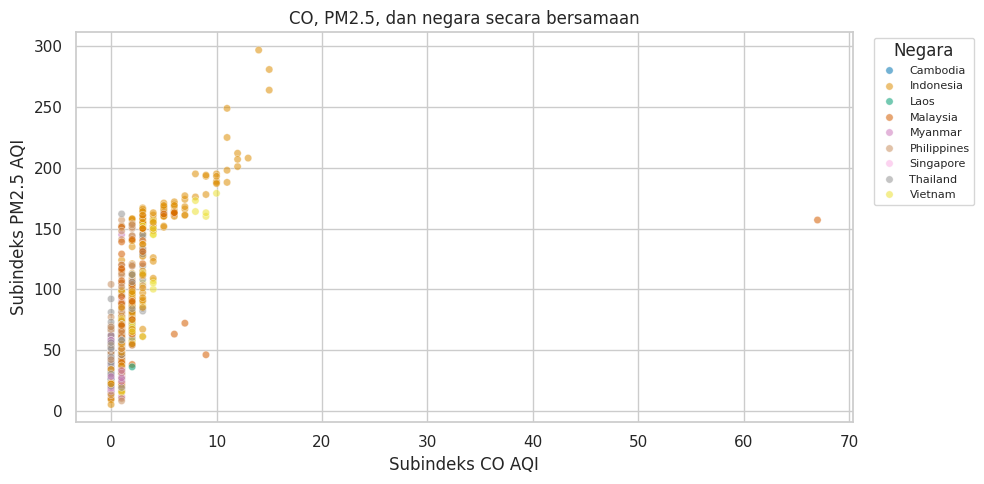

**Analisis:** korelasi peringkat CO–PM2.5 pada gabungan sampel adalah **0.755**. Titik mengelompok pada CO bernilai kecil dan tersebar lebar pada PM2.5. Warna membantu menelaah perbedaan antarnegara, tetapi tumpang tindih dan jumlah kota yang tidak seimbang membatasi perbandingan. Hubungan gabungan tidak otomatis sama dengan hubungan di dalam setiap negara.

In [7]:
fig, ax = plt.subplots(figsize=(10,5))
sns.scatterplot(data=asean, x='CO AQI Value', y='PM2.5 AQI Value', hue='Country', hue_order=sorted(asean.Country.unique()), alpha=.55, s=28, ax=ax)
ax.legend(bbox_to_anchor=(1.02,1), loc='upper left', title='Negara', fontsize=8)
ax.set(xlabel='Subindeks CO AQI', ylabel='Subindeks PM2.5 AQI', title='CO, PM2.5, dan negara secara bersamaan')
savefig('05_multivariat_scatter')
co_pm = asean[['CO AQI Value','PM2.5 AQI Value']].corr(method='spearman').iloc[0,1]
display(Markdown(f"**Analisis:** korelasi peringkat CO–PM2.5 pada gabungan sampel adalah **{co_pm:.3f}**. Titik mengelompok pada CO bernilai kecil dan tersebar lebar pada PM2.5. Warna membantu menelaah perbedaan antarnegara, tetapi tumpang tindih dan jumlah kota yang tidak seimbang membatasi perbandingan. Hubungan gabungan tidak otomatis sama dengan hubungan di dalam setiap negara."))


### 5.2 Matriks korelasi polutan dan profil negara
Heatmap korelasi merangkum pasangan di dalam kumpulan empat variabel; scatterplot sebelumnya secara eksplisit memetakan tiga variabel. Profil median negara memakai skala warna terpisah per kolom agar CO/NO2 yang kecil tidak hilang dibanding PM2.5; angka anotasi tetap indeks asli.

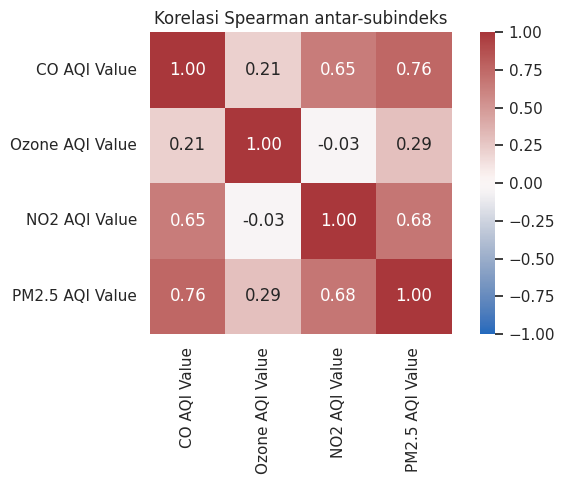

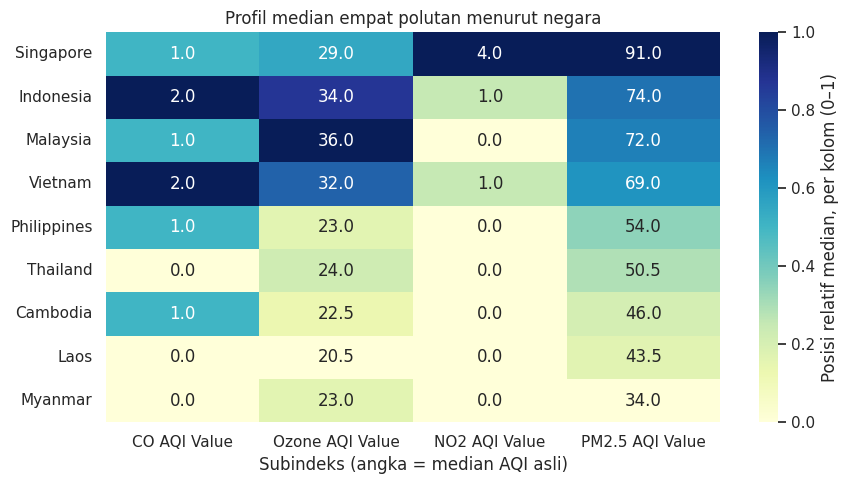

,CO AQI Value,Ozone AQI Value,NO2 AQI Value,PM2.5 AQI Value
Country,,,,
Singapore,1.0,29.0,4.0,91.0
Indonesia,2.0,34.0,1.0,74.0
Malaysia,1.0,36.0,0.0,72.0
Vietnam,2.0,32.0,1.0,69.0
Philippines,1.0,23.0,0.0,54.0
Thailand,0.0,24.0,0.0,50.5
Cambodia,1.0,22.5,0.0,46.0
Laos,0.0,20.5,0.0,43.5
Myanmar,0.0,23.0,0.0,34.0


**Analisis:** pasangan polutan dengan asosiasi peringkat absolut terbesar adalah **CO AQI Value dan PM2.5 AQI Value** (ρ=0.755). Profil negara memperlihatkan bahwa nilai median subindeks tidak selalu bergerak seragam. Warna dinormalisasi per kolom: warna yang sama pada dua polutan tidak berarti nilai AQI asli sama. Korelasi dan profil ini bersifat eksploratif, bukan identifikasi sumber emisi.

In [8]:
fig, ax = plt.subplots(figsize=(7,5))
corr = asean[pollutants].corr(method='spearman')
sns.heatmap(corr, vmin=-1, vmax=1, center=0, cmap='vlag', annot=True, fmt='.2f', square=True, ax=ax)
ax.set_title('Korelasi Spearman antar-subindeks'); savefig('06_korelasi')
profiles = asean.groupby('Country')[pollutants].median().loc[order]
denom = profiles.max() - profiles.min()
relative = (profiles - profiles.min()) / denom.replace(0,1)
fig, ax = plt.subplots(figsize=(9,5))
sns.heatmap(relative, annot=profiles, fmt='.1f', cmap='YlGnBu', vmin=0, vmax=1, ax=ax, cbar_kws={'label':'Posisi relatif median, per kolom (0–1)'})
ax.set(xlabel='Subindeks (angka = median AQI asli)', ylabel='', title='Profil median empat polutan menurut negara')
savefig('07_profil')
display(profiles)
pairs = corr.where(np.triu(np.ones(corr.shape),k=1).astype(bool)).stack()
strongest = pairs.abs().idxmax()
display(Markdown(f"**Analisis:** pasangan polutan dengan asosiasi peringkat absolut terbesar adalah **{strongest[0]} dan {strongest[1]}** (ρ={pairs.loc[strongest]:.3f}). Profil negara memperlihatkan bahwa nilai median subindeks tidak selalu bergerak seragam. Warna dinormalisasi per kolom: warna yang sama pada dua polutan tidak berarti nilai AQI asli sama. Korelasi dan profil ini bersifat eksploratif, bukan identifikasi sumber emisi."))


## 6. Kesimpulan dan tindak lanjut

1. Distribusi AQI dalam sampel memiliki ekor kanan; median dan IQR melengkapi rata-rata agar nilai ekstrem tidak mendominasi ringkasan.
2. Kategori Moderate paling banyak. Sebagian kota tercatat pada AQI >100, sehingga variasi antarkota relevan untuk kajian lanjutan.
3. Perbandingan negara harus menyertakan ukuran sampel. Hasil tidak dapat digunakan sebagai peringkat kualitas udara nasional berbobot populasi.
4. PM2.5 sering menyamai AQI gabungan; hubungan ini perlu dibaca bersama sifat maksimum subindeks, bukan sebagai temuan kausal baru.
5. Analisis multivariat menunjukkan profil polutan yang beragam. Untuk penelitian lanjutan, dibutuhkan waktu pengukuran, sumber primer, metode sensor, koordinat tervalidasi, dan cakupan kota yang sebanding. Tidak ada rekomendasi penyebab emisi spesifik yang dapat ditetapkan hanya dari CSV ini.

**Perbaikan atas notebook referensi:** penyamaan nama Vietnam/Laos; pembetulan interval kategori; mempertahankan nilai ekstrem untuk EDA; menghilangkan ketergantungan geocoding; membatasi klaim korelasi; serta menambahkan analisis tertulis untuk tiap tingkat visualisasi.

## 7. Reproduksibilitas dan referensi

Jalankan seluruh sel dari folder yang memuat notebook dan subfolder `data`. Dataset asli tidak diubah; subset dan ringkasan ditulis sebagai berkas terpisah. Dependensi dan versi disertakan di `requirements.txt`. Notebook tidak memerlukan jaringan saat eksekusi.

- Kaggle: halaman input notebook kimpilso, tautan pada bagian 1, diberikan pengguna.
- Notebook referensi unggahan: `asean-air-pollution-capstone-g5-ds-greatedu.ipynb`.
- CSV unggahan: `global_air_pollution_dataset.csv.zip`; sidik SHA256 dicetak pada bagian 1.

Sebelum unggah LMS: isi identitas dan verifikasi metadata sumber, lisensi, serta periode pengukuran jika tersedia pada halaman Kaggle. Tidak ada tanggal pengukuran atau status kualitas udara terkini yang diasumsikan.

In [9]:
summary = {
    'global_rows':len(df), 'regional_rows':len(asean), 'countries':int(asean.Country.nunique()),
    'median_aqi':float(asean['AQI Value'].median()), 'mean_aqi':float(asean['AQI Value'].mean()),
    'share_above100_pct':float(share_above100), 'pm25_pearson':float(r),
    'max_match_pct':float(max_match*100), 'pm25_match_pct':float(pm_match*100),
    'category_counts':{str(k):int(v) for k,v in counts.items()},
    'source_url': 'https://www.kaggle.com/code/kimpilso/asean-air-pollution-capstone-g5-ds-greatedu/input',
    'dataset_sha256':hashlib.sha256(DATA.read_bytes()).hexdigest()
}
Path('data/hasil_ringkas.json').write_text(json.dumps(summary, indent=2))
print('Analisis selesai; 7 gambar, subset, dan ringkasan tersimpan.')


Analisis selesai; 7 gambar, subset, dan ringkasan tersimpan.
